# 4 · Perbandingan Model: LSTM vs Bi-LSTM vs ConvLSTM

Notebook ini membandingkan **tiga arsitektur model** pada dua skema fitur gerakan, **tanpa augmentasi data**:

| | Pilihan |
|---|---|
| Skema fitur | **C** (gerakan sudut, 16 fitur) dan **D** (gerakan koordinat, 52 fitur) |
| Mode sekuens | **resample** (60 frame) dan **window** (30 frame) |
| Model | **LSTM**, **Bi-LSTM**, **ConvLSTM** |
| Evaluasi | holdout + LOSO (9 fold), uji urutan diacak |

Total: 3 model × 2 skema × 2 mode × 10 fold = **120 training**.

**Tiga model yang dibandingkan:**

| Model | Cara membaca gerakan | Perumpamaan |
|---|---|---|
| **LSTM** | membaca urutan frame **dari awal ke akhir** (satu arah) | membaca kalimat dari kiri ke kanan |
| **Bi-LSTM** (*Bidirectional LSTM*) | dua LSTM: satu membaca **maju**, satu membaca **mundur**, hasilnya digabung | membaca kalimat dua kali, dari depan dan dari belakang, supaya paham konteks utuh |
| **ConvLSTM** (*Convolutional LSTM*) | di setiap frame, melihat **sendi-sendi yang berdekatan sekaligus** (konvolusi), lalu mengikuti perubahannya dari waktu ke waktu | memperhatikan gerakan bahu-siku-pergelangan sebagai satu kesatuan, bukan satu per satu |

**Supaya perbandingannya adil**, semua model memakai data, split, normalisasi, learning rate, batch size, dan jumlah epoch yang **sama** dengan LSTM di `2_training_tanpa_augmentasi.ipynb` (dari `results/tanpa_augmentasi/best_config.csv`). Yang berbeda hanya arsitektur modelnya.

Hasil disimpan ke `results/perbandingan_model/`. Progres dapat dipantau di terminal: `tail -f results/perbandingan_model/progress.log`.

## 1. Setup & Konfigurasi

**💡 Penjelasan kode**

- Library yang sama dengan notebook 2: TensorFlow untuk model, joblib untuk training paralel, scikit-learn untuk metrik.
- `TF_NUM_INTRAOP_THREADS = 2`: setiap model memakai 2 thread CPU, sehingga beberapa model bisa dilatih bersamaan.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # sembunyikan log TensorFlow yang tidak penting
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")    # 2 thread per model -> beberapa model bisa paralel
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

**💡 Penjelasan kode**

- `SCHEMES = ["C", "D"]`: hanya dua skema fitur gerakan.
- `MODELS`: tiga arsitektur yang dibandingkan.
- `N_JOINTS`: jumlah "sendi" di setiap skema, dipakai ConvLSTM untuk menyusun fitur per sendi. Skema C punya 8 sudut sendi, Skema D punya 13 keypoints.
- `best_cfg`: learning rate, batch size, dan jumlah epoch dibaca dari hasil tuning notebook 2, sehingga **sama untuk ketiga model**.
- `QUICK = True` hanya untuk uji coba cepat. Untuk hasil akhir harus `False`.

In [2]:
# ---------------- Path ----------------
ROOT = Path.cwd()
FEAT_DIR = ROOT / "data" / "features"
SPLITS_JSON = ROOT / "data" / "splits.json"
BEST_CONFIG_CSV = ROOT / "results" / "tanpa_augmentasi" / "best_config.csv"  # hasil tuning notebook 2
OUT_DIR = ROOT / "results" / "perbandingan_model"
FIG_DIR, MODEL_DIR = OUT_DIR / "figures", OUT_DIR / "models"
for d in (OUT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
CLASS_NAMES = ["Lat_Pulldown", "Seated_Cable_Row", "Bent_over"]  # label 0, 1, 2
SHORT_NAMES = ["Lat Pulldown", "Seated Row", "Bent Over"]
TARGET_W, TARGET_H = 720, 1280

# ---------------- Skema, sekuens, model ----------------
SCHEMES = ["C", "D"]
SEQ_MODES = ["resample", "window"]
MODELS = ["LSTM", "Bi-LSTM", "ConvLSTM"]
N_JOINTS = {"C": 8, "D": 13}       # 8 sudut sendi (C), 13 keypoints (D)
RESAMPLE_LEN = 60
WINDOW_SIZE, WINDOW_STRIDE = 30, 10
DROPOUT, DENSE_UNITS = 0.3, 32      # bagian akhir model, sama untuk ketiga model

# ---------------- Hyperparameter (sama dengan LSTM di notebook 2) ----------------
assert BEST_CONFIG_CSV.exists(), "Jalankan 2_training_tanpa_augmentasi.ipynb terlebih dahulu"
best_cfg = pd.read_csv(BEST_CONFIG_CSV).set_index(["scheme", "mode"]).loc[SCHEMES]

N_JOBS = 5      # jumlah model yang dilatih bersamaan
QUICK = False   # True = uji coba cepat; hasil akhir harus False
if QUICK:
    best_cfg["max_epoch"] = 3

PROGRESS_LOG = OUT_DIR / "progress.log"
PROGRESS_LOG.write_text("")
_T0 = time.time()


def log_progress(done, total, info=""):
    pct = done / total
    bar = "#" * int(pct * 20) + "-" * (20 - int(pct * 20))
    with open(PROGRESS_LOG, "a") as f:
        f.write(f"[{time.strftime('%H:%M:%S')}] [{bar}] {done}/{total} ({pct:.0%}) {info} "
                f"| berjalan {(time.time() - _T0) / 60:.1f} menit\n")


best_cfg[["lr", "batch", "max_epoch"]]

lr  batch  max_epoch
scheme mode                              
C      resample  0.0010     16        100
       window    0.0001     16         50
D      resample  0.0010     16        100
       window    0.0010     32        100

## 2. Memuat Data & Membuat Fitur C dan D

Kode di bagian ini **sama persis** dengan notebook 2, supaya datanya identik.

**💡 Penjelasan kode**

- `load_keypoints`: membaca CSV Skema A menjadi array (frame, 13 keypoints, 4 nilai).
- `RAW[video_id]`: keypoints setiap video (hanya data asli, tanpa augmentasi).

In [3]:
index = pd.read_csv(FEAT_DIR / "index.csv")
index = index[~index.excluded].reset_index(drop=True)
splits = json.loads(SPLITS_JSON.read_text())
LABEL = dict(zip(index.video_id, index.label))


def load_keypoints(path):
    # CSV format Skema A -> (T, 13, 4): x, y, z, visibility
    return pd.read_csv(path).drop(columns="frame").to_numpy(np.float32).reshape(-1, 13, 4)


RAW = {r.video_id: [load_keypoints(FEAT_DIR / r.schemeA_path)] for r in index.itertuples()}  # video_id -> [asli]

print(f"{len(RAW)} video (data asli saja)")
print("Holdout:", {k: v["subjects"] for k, v in splits["holdout"].items()})

240 video (data asli saja)
Holdout: {'train': [2, 3, 4, 5, 6, 8, 9, 10], 'val': [7], 'test': [1]}


**💡 Penjelasan kode**

Fungsi-fungsi pembuat fitur (sama dengan notebook 2):
- **C** = 8 sudut sendi − rata-ratanya dalam video, ditambah kecepatan sudut → 16 fitur: `[8 perubahan sudut, 8 kecepatan sudut]`.
- **D** = koordinat (x, y) dipusatkan di pinggul dan dibagi panjang badan, dikurangi rata-ratanya, ditambah kecepatan → 52 fitur: `[26 perubahan koordinat, 26 kecepatan]`.

Urutan fitur ini penting untuk ConvLSTM, karena di sana fitur disusun ulang **per sendi** (lihat bagian 3).

In [4]:
# 8 sudut sendi (Tabel 3.3) dalam indeks 13 keypoints: (A, B, C), B = sendi yang diukur
# 0 nose, 1/2 bahu kiri/kanan, 3/4 siku, 5/6 pergelangan tangan, 7/8 pinggul, 9/10 lutut, 11/12 pergelangan kaki
ANGLE_TRIPLETS = [(7, 1, 3), (8, 2, 4), (1, 3, 5), (2, 4, 6), (1, 7, 9), (2, 8, 10), (7, 9, 11), (8, 10, 12)]


def pixel_xy(raw):
    return raw[..., :2] * np.array([TARGET_W, TARGET_H], np.float32)


def centered_xy(raw):
    xy = pixel_xy(raw)
    hip = xy[:, [7, 8]].mean(1, keepdims=True)            # tengah pinggul tiap frame
    shoulder = xy[:, [1, 2]].mean(1, keepdims=True)       # tengah bahu tiap frame
    torso = np.median(np.linalg.norm(shoulder - hip, axis=-1))
    return ((xy - hip) / torso).reshape(len(raw), -1)     # (T, 26): x0, y0, x1, y1, ...


def joint_angles(raw):
    xy = pixel_xy(raw)
    out = np.empty((len(raw), len(ANGLE_TRIPLETS)), np.float32)
    for j, (a, b, c) in enumerate(ANGLE_TRIPLETS):
        ba, bc = xy[:, a] - xy[:, b], xy[:, c] - xy[:, b]
        deg = np.abs(np.degrees(np.arctan2(bc[:, 1], bc[:, 0]) - np.arctan2(ba[:, 1], ba[:, 0]))) % 360
        out[:, j] = np.where(deg > 180, 360 - deg, deg)
    return out


def velocity(f):
    return np.diff(f, axis=0, prepend=f[:1])


def make_features(scheme, raw):
    if scheme == "A":
        return raw.reshape(len(raw), -1)
    if scheme == "A'":
        return centered_xy(raw)
    if scheme == "B":
        return joint_angles(raw)
    if scheme == "C":
        a = joint_angles(raw)
        return np.concatenate([a - a.mean(0), velocity(a)], axis=1)
    if scheme == "D":
        xy = centered_xy(raw)
        return np.concatenate([xy - xy.mean(0), velocity(xy)], axis=1)
    raise ValueError(scheme)


FEATURES = {s: {v: [make_features(s, r).astype(np.float32) for r in versions] for v, versions in RAW.items()}
            for s in SCHEMES}

for s in SCHEMES:
    print(f"Skema {s:2s}: {FEATURES[s][index.video_id[0]][0].shape[1]:2d} fitur per frame")

Skema C : 16 fitur per frame
Skema D : 52 fitur per frame


## 3. Sekuens & Tiga Arsitektur Model

Persiapan sekuens (resample/window), metrik, dan pembagian LOSO sama dengan notebook 2.

**💡 Penjelasan kode**

Sama dengan notebook 2:
- `to_samples`, `build_set`: mengubah video menjadi sampel resample (60 frame) atau window (30 frame). `shuffle=True` mengacak urutan frame (uji urutan diacak).
- `metrics`: akurasi, presisi, recall, F1 (macro).
- `video_pred`: rata-rata prediksi potongan window menjadi prediksi per video.
- `videos_of`, `loso_folds`: pembagian subjek untuk LOSO.

In [5]:
def to_samples(seq, mode, shuffle_rng=None):
    if mode == "resample":
        t_old, t_new = np.linspace(0, 1, len(seq)), np.linspace(0, 1, RESAMPLE_LEN)
        seq = np.stack([np.interp(t_new, t_old, seq[:, j]) for j in range(seq.shape[1])], axis=1)
        if shuffle_rng is not None:
            seq = seq[shuffle_rng.permutation(len(seq))]
        return [seq]
    if shuffle_rng is not None:
        seq = seq[shuffle_rng.permutation(len(seq))]
    return [seq[s:s + WINDOW_SIZE] for s in range(0, len(seq) - WINDOW_SIZE + 1, WINDOW_STRIDE)]


def build_set(scheme, mode, video_ids, augment=False, shuffle=False):
    rng = np.random.default_rng(SEED) if shuffle else None
    X, y, vid_idx = [], [], []
    for i, v in enumerate(video_ids):
        versions = FEATURES[scheme][v] if augment else FEATURES[scheme][v][:1]  # [:1] = data asli saja
        for seq in versions:
            parts = to_samples(seq, mode, rng)
            X += parts
            y += [LABEL[v]] * len(parts)
            vid_idx += [i] * len(parts)
    return np.asarray(X, np.float32), np.asarray(y), np.asarray(vid_idx)


def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f}


def video_pred(proba, vid_idx, n_videos):
    return np.stack([proba[vid_idx == i].mean(0) for i in range(n_videos)]).argmax(1)


def videos_of(subjects):
    return sorted(index[index.subject.isin(subjects)].video_id)


def loso_folds():
    units = [f["test_subjects"] for f in splits["loso"]]
    for k, test_u in enumerate(units):
        val_u = units[(k + 1) % len(units)]
        yield k, [s for u in units if u not in (test_u, val_u) for s in u], val_u, test_u

### Arsitektur ketiga model

Bagian awal model berbeda-beda, sedangkan **bagian akhirnya sama**: `Dropout(0,3) → Dense(32, ReLU) → Dense(3, Softmax)`.

| Model | Bagian awal | Keterangan |
|---|---|---|
| **LSTM** | `LSTM(64)` → `LSTM(32)` | sesuai Gambar 3.3 proposal |
| **Bi-LSTM** | `Bidirectional(LSTM(64))` → `Bidirectional(LSTM(32))` | setiap layer punya 2 LSTM (maju & mundur), jadi parameternya sekitar 2,5× LSTM |
| **ConvLSTM** | susun ulang per sendi → `ConvLSTM1D(32)` → `ConvLSTM1D(16)` | ukuran dipilih supaya jumlah parameternya mirip LSTM |

**Penyusunan ulang per sendi untuk ConvLSTM.** Input biasa berbentuk (waktu, fitur). ConvLSTM butuh bentuk (waktu, **sendi**, nilai per sendi), supaya konvolusi bisa melihat sendi-sendi yang berdekatan:
- Skema C: (waktu, 16) → (waktu, **8 sudut**, 2), dengan nilai per sudut = [perubahan, kecepatan].
- Skema D: (waktu, 52) → (waktu, **13 keypoints**, 4), dengan nilai per keypoint = [perubahan x, perubahan y, kecepatan x, kecepatan y].

`kernel_size = 3` berarti setiap langkah konvolusi melihat **3 sendi berurutan** sekaligus, misalnya bahu kanan, siku kiri, siku kanan.

**💡 Penjelasan kode**

- `build_model(arch, input_shape, n_joints)`: membuat salah satu dari tiga model.
  - `L.Bidirectional(L.LSTM(...))`: membungkus LSTM supaya membaca urutan maju **dan** mundur, lalu hasil keduanya digabung.
  - `L.Reshape` dan `L.Permute`: menyusun ulang fitur dari `[semua perubahan, semua kecepatan]` menjadi per sendi `[perubahan, kecepatan]`.
  - `L.ConvLSTM1D`: LSTM yang di dalamnya memakai konvolusi, sehingga setiap langkah waktu memproses sendi-sendi berdekatan bersama.
- `fit_predict(...)`: sama seperti notebook 2 (normalisasi dengan data latih, checkpoint val_loss terendah), ditambah:
  - parameter `arch` untuk memilih model;
  - mencatat **jumlah parameter** dan **waktu training** (detik), untuk membandingkan seberapa "berat" setiap model.
- Sel ini juga menampilkan ringkasan (`summary`) ketiga model untuk Skema C resample, supaya bentuk setiap layer terlihat.

In [6]:
def build_model(arch, input_shape, n_joints):
    import tensorflow as tf
    L = tf.keras.layers
    T, F = input_shape
    inp = tf.keras.Input(shape=input_shape)
    if arch == "LSTM":
        x = L.LSTM(64, return_sequences=True)(inp)
        x = L.LSTM(32)(x)
    elif arch == "Bi-LSTM":
        x = L.Bidirectional(L.LSTM(64, return_sequences=True))(inp)
        x = L.Bidirectional(L.LSTM(32))(x)
    elif arch == "ConvLSTM":
        k = F // (2 * n_joints)                       # nilai per sendi di tiap blok (C: 1, D: 2)
        x = L.Reshape((T, 2, n_joints, k))(inp)       # [blok perubahan, blok kecepatan]
        x = L.Permute((1, 3, 2, 4))(x)                # -> (waktu, sendi, blok, nilai)
        x = L.Reshape((T, n_joints, 2 * k))(x)        # -> (waktu, sendi, nilai per sendi)
        x = L.ConvLSTM1D(32, kernel_size=3, padding="same", return_sequences=True)(x)
        x = L.ConvLSTM1D(16, kernel_size=3, padding="same")(x)
        x = L.Flatten()(x)
    else:
        raise ValueError(arch)
    x = L.Dropout(DROPOUT)(x)
    x = L.Dense(DENSE_UNITS, activation="relu")(x)
    out = L.Dense(3, activation="softmax")(x)
    return tf.keras.Model(inp, out, name=arch.replace("-", ""))


def fit_predict(arch, n_joints, Xtr, ytr, Xva, yva, test_sets, lr, batch, epochs, seed=SEED, save_path=None):
    import os
    import time
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
    import numpy as np
    import tensorflow as tf

    flat = Xtr.reshape(-1, Xtr.shape[-1])
    mean, std = flat.mean(0), flat.std(0) + 1e-8
    norm = lambda X: (X - mean) / std

    tf.keras.utils.set_random_seed(seed)
    model = build_model(arch, Xtr.shape[1:], n_joints)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="categorical_crossentropy", metrics=["accuracy"])

    class Best(tf.keras.callbacks.Callback):
        best = (np.inf, 0, None)

        def on_epoch_end(self, epoch, logs=None):
            if logs["val_loss"] < self.best[0]:
                self.best = (logs["val_loss"], epoch + 1, self.model.get_weights())

    cb = Best()
    t0 = time.time()
    hist = model.fit(norm(Xtr), tf.keras.utils.to_categorical(ytr, 3), batch_size=batch, epochs=epochs,
                     validation_data=(norm(Xva), tf.keras.utils.to_categorical(yva, 3)),
                     shuffle=True, verbose=0, callbacks=[cb])
    train_seconds = time.time() - t0

    model.set_weights(cb.best[2])
    if save_path is not None:
        model.save(save_path)
    history = {k: [float(x) for x in v] for k, v in hist.history.items()}
    probas = [model.predict(norm(X), verbose=0) for X in test_sets]
    return probas, history, cb.best[1], model.count_params(), train_seconds


# Ringkasan arsitektur untuk Skema C, mode resample (input 60 frame x 16 fitur)
for arch in MODELS:
    build_model(arch, (RESAMPLE_LEN, 16), N_JOINTS["C"]).summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 60, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 60, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,307 (134.01 KB)

 Trainable params: 34,307 (134.01 KB)

 Non-trainable params: 0 (0.00 B)

...

Model: "ConvLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 60, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 60, 2, 8, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 60, 8, 2, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 60, 8, 2)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm1d (ConvLSTM1D)        │ (None, 60, 8, 32)      │        13,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm1d_1 (ConvLSTM1D)      │ (None, 8, 16)          │         9,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,691 (104.26 KB)

 Trainable params: 26,691 (104.26 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Training & Evaluasi

Untuk setiap model × skema × mode: **1 run holdout + 9 run LOSO**. Setiap run juga diuji dengan **urutan frame diacak**.

**💡 Penjelasan kode**

- `all_folds()`: daftar pembagian data (1 holdout + 9 LOSO), sama dengan notebook 2.
- `job_stream()`: membuat data setiap run lalu mengirim `fit_predict` ke proses paralel. Model holdout disimpan ke `models/<model>_<skema>_<mode>.keras`.
- Hasil yang disimpan:
  - `runs.csv`: metrik setiap run, ditambah jumlah parameter dan waktu training;
  - `predictions.csv`: prediksi setiap video uji (bahan confusion matrix);
  - `histories.json`: loss per epoch run holdout (bahan learning curve).
- **Ini sel paling lama** (perkiraan 45–90 menit; Bi-LSTM dan ConvLSTM lebih lambat dari LSTM). Pantau dengan `tail -f results/perbandingan_model/progress.log`.

In [7]:
def all_folds():
    H = splits["holdout"]
    yield "holdout", H["train"]["videos"], H["val"]["videos"], H["test"]["videos"], H["test"]["subjects"]
    for k, tr, va, te in loso_folds():
        yield f"loso{k}", videos_of(tr), videos_of(va), videos_of(te), te


meta = []


def job_stream():
    for arch in MODELS:
        for s in SCHEMES:
            for m in SEQ_MODES:
                cfg = best_cfg.loc[(s, m)]
                for fold, tr, va, te, te_subj in all_folds():
                    Xtr, ytr, _ = build_set(s, m, tr)
                    Xva, yva, _ = build_set(s, m, va)
                    Xte, _, vte = build_set(s, m, te)
                    Xsh, _, vsh = build_set(s, m, te, shuffle=True)
                    save = str(MODEL_DIR / f"{arch}_{s}_{m}.keras") if fold == "holdout" else None
                    meta.append({"model": arch, "scheme": s, "mode": m, "fold": fold, "test_subjects": str(te_subj),
                                 "te": te, "vte": vte, "vsh": vsh})
                    yield delayed(fit_predict)(arch, N_JOINTS[s], Xtr, ytr, Xva, yva, [Xte, Xsh], float(cfg.lr),
                                               int(cfg.batch), int(cfg.max_epoch), save_path=save)


n_total = len(MODELS) * len(SCHEMES) * len(SEQ_MODES) * (1 + len(splits["loso"]))
print(f"{n_total} training dengan {N_JOBS} proses paralel ...")
rows, pred_rows, histories = [], [], {}
results = Parallel(n_jobs=N_JOBS, return_as="generator", pre_dispatch="2*n_jobs")(job_stream())
for n, (probas, hist, best_ep, n_params, secs) in enumerate(results, 1):
    m = meta[n - 1]
    y_true = np.array([LABEL[v] for v in m["te"]])
    y_pred = video_pred(probas[0], m["vte"], len(m["te"]))
    y_shuf = video_pred(probas[1], m["vsh"], len(m["te"]))
    key = {k: m[k] for k in ("model", "scheme", "mode", "fold", "test_subjects")}
    rows.append(key | metrics(y_true, y_pred) | {"shuffled_accuracy": accuracy_score(y_true, y_shuf),
                                                 "best_epoch": best_ep, "n_params": n_params, "train_seconds": secs})
    pred_rows += [{"model": m["model"], "scheme": m["scheme"], "mode": m["mode"], "fold": m["fold"],
                   "video_id": v, "label": t, "pred": p} for v, t, p in zip(m["te"], y_true, y_pred)]
    if m["fold"] == "holdout":
        histories[f"{m['model']}|{m['scheme']}|{m['mode']}"] = hist
    log_progress(n, n_total, f"{m['model']} | skema {m['scheme']} | {m['mode']} | {m['fold']}")

runs = pd.DataFrame(rows)
preds = pd.DataFrame(pred_rows)
runs.to_csv(OUT_DIR / "runs.csv", index=False)
preds.to_csv(OUT_DIR / "predictions.csv", index=False)
(OUT_DIR / "histories.json").write_text(json.dumps(histories))
print(f"Selesai dalam {(time.time() - _T0) / 60:.1f} menit")

120 training dengan 5 proses paralel ...


/Users/albobchai/Library/Python/3.11/lib/python/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/albobchai/Library/Python/3.11/lib/python/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/albobchai/Library/Python/3.11/lib/python/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/albobchai/Library/Python/3.11/lib/python/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This ca

Selesai dalam 43.5 menit


## 5. Hasil per Skema

Untuk Skema C dan D masing-masing ditampilkan:

1. **Tabel metrik**: akurasi, presisi, recall, F1 (LOSO rata-rata ± std), akurasi holdout, uji urutan diacak, jumlah parameter, dan waktu training per run.
2. **Learning curve** (run holdout): baris = model, kolom = mode.
3. **Confusion matrix LOSO gabungan** (240 video): baris = mode, kolom = model.
4. **Laporan per kelas** (LOSO gabungan).
5. **Akurasi LOSO per subjek**.

**Cara membaca learning curve** (sama dengan notebook 2):
- 🔵 biru = data latih, 🟠 oranye = data validasi (orang baru). Loss = tingkat kesalahan, **makin bawah makin baik**.
- ⭐ = titik loss validasi terendah. Bobot dari titik inilah yang dipakai.
- 🟩 hijau = belajar sehat, 🟥 merah = overfitting (oranye naik lagi sementara biru terus turun), 🟨 kuning = naik-turun tajam.

**💡 Penjelasan kode**

Fungsi-fungsi pembuat laporan:
- `cm_of(model, scheme, mode, fold)`: confusion matrix dari `predictions.csv`.
- `plot_cm`, `plot_learning_curve_sederhana`: sama dengan notebook 2.
- `laporan_skema(scheme)`: menampilkan kelima bagian laporan untuk satu skema, dan menyimpan gambarnya ke `figures/learning_curve_<skema>.png` dan `figures/confusion_matrix_<skema>.png`.

In [8]:
METRICS = ["accuracy", "precision", "recall", "f1"]
METRIC_ID = {"accuracy": "Akurasi", "precision": "Presisi", "recall": "Recall", "f1": "F1-score"}


def cm_of(model, scheme, mode, fold):
    p = preds[(preds.model == model) & (preds.scheme == scheme) & (preds["mode"] == mode) & preds.fold.str.startswith(fold)]
    return confusion_matrix(p.label, p.pred, labels=range(3))


def plot_cm(ax, cm, title):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum(1).max())
    for a in range(3):
        for b in range(3):
            wrong = a != b and cm[a, b] > 0
            ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=13, fontweight="bold" if wrong else "normal",
                    color="#C0392B" if wrong else ("white" if cm[a, b] > cm.sum(1).max() / 2 else "black"))
    ax.set_xticks(range(3), SHORT_NAMES, rotation=20, fontsize=8)
    ax.set_yticks(range(3), SHORT_NAMES, fontsize=8)
    ax.set_xlabel("Prediksi", fontsize=9)
    ax.set_ylabel("Aktual", fontsize=9)
    acc = np.trace(cm) / cm.sum()
    ax.set_title(f"{title}\nakurasi {acc:.1%} ({cm.sum() - np.trace(cm)} salah dari {cm.sum()})", fontsize=10)


def plot_learning_curve_sederhana(ax, hist, mode):
    # Loss bisa sangat kecil sampai tercatat 0; dibatasi 1e-7 supaya bisa digambar di skala log
    train, val = np.maximum(hist["loss"], 1e-7), np.maximum(hist["val_loss"], 1e-7)
    epochs = np.arange(1, len(val) + 1)
    best = int(val.argmin()) + 1
    # Overfitting: setelah titik terbaik, loss validasi naik > 2x sementara loss latih terus turun
    # (loss latih akhir lebih rendah dari loss latih terendah sampai titik terbaik)
    overfit = (val[-1] > 2 * val.min() and val[-1] - val.min() > 0.005
               and best < len(val) and train[-1] < train[:best].min())
    # Tidak stabil: loss validasi beberapa kali melonjak > 5x dari epoch sebelumnya
    spikes = int(np.sum((val[1:] > 5 * val[:-1]) & (val[1:] > 0.01)))
    unstable = not overfit and spikes >= 2

    # Zona latar: hijau = masih belajar, merah = overfitting, kuning = tidak stabil
    if unstable:
        ax.axvspan(0.5, len(val) + 0.5, color="#F1C40F", alpha=0.12)
        ax.text(0.5, 0.97, f"NAIK-TURUN TAJAM\n(loss validasi {spikes}x melonjak)", transform=ax.transAxes,
                ha="center", va="top", fontsize=10, color="#9A7D0A", fontweight="bold")
    else:
        ax.axvspan(0.5, best, color="#2ECC71", alpha=0.12)
        ax.text((best + 1) / 2, 0.97, "BELAJAR\n(latih & validasi turun)", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=10, color="#1E8449", fontweight="bold")
    if overfit:
        ax.axvspan(best, len(val) + 0.5, color="#E74C3C", alpha=0.12)
        ax.text((best + len(val)) / 2, 0.97, "OVERFITTING\n(validasi naik lagi)", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=10, color="#B03A2E", fontweight="bold")

    ax.plot(epochs, train, color="#1F4E79", lw=2.5, label="Data latih (yang dipelajari)")
    ax.plot(epochs, val, color="#E67E22", lw=2.5, label="Data validasi (orang baru)")
    ax.plot(best, val.min(), marker="*", ms=22, color="#F1C40F", markeredgecolor="black", zorder=5)
    ax.annotate(f"Titik terbaik: epoch {best}\n(model ini yang dipakai)", xy=(best, val.min()),
                xytext=(0.5, 0.35), textcoords="axes fraction", ha="center", fontsize=10,
                arrowprops=dict(arrowstyle="->", color="black"),
                bbox=dict(boxstyle="round", fc="white", ec="gray"))

    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.10f}".rstrip("0").rstrip(".").replace(".", ",")))
    ax.set_xlim(0.5, len(val) + 0.5)
    ax.set_xlabel("Epoch (berapa kali model sudah belajar dari seluruh data latih)")
    ax.set_ylabel("Loss = tingkat kesalahan\n(makin BAWAH makin BAIK)")
    if overfit:
        verdict, color = f"Overfitting setelah epoch {best}", "#B03A2E"
    elif unstable:
        verdict, color = "Kurang stabil (naik-turun)", "#9A7D0A"
    else:
        verdict, color = "Sehat: terus membaik", "#1E8449"
    ax.set_title(f"Mode {mode}  →  {verdict}", fontsize=12, fontweight="bold", color=color)
    ax.legend(loc="lower left", fontsize=9)
    ax.grid(alpha=0.3)


def laporan_skema(scheme):
    r = runs[runs.scheme == scheme]
    loso = r[r.fold.str.startswith("loso")]
    hold = r[r.fold == "holdout"].set_index(["model", "mode"])

    # 1. Tabel metrik
    table = {}
    for arch in MODELS:
        for mode in SEQ_MODES:
            l = loso[(loso.model == arch) & (loso["mode"] == mode)]
            row = {METRIC_ID[k]: f"{l[k].mean():.1%} ± {l[k].std():.1%}" for k in METRICS}
            row["Holdout akurasi"] = f"{hold.loc[(arch, mode), 'accuracy']:.1%}"
            row["Urutan diacak"] = f"{l.shuffled_accuracy.mean():.1%}"
            row["Parameter"] = f"{int(l.n_params.iloc[0]):,}".replace(",", ".")
            row["Waktu/run (detik)"] = f"{r[(r.model == arch) & (r['mode'] == mode)].train_seconds.mean():.0f}"
            table[(arch, mode)] = row
    display(Markdown("**1. Tabel metrik (LOSO rata-rata ± std)**"))
    display(pd.DataFrame(table).T)

    # 2. Learning curve
    display(Markdown("**2. Learning curve (run holdout)**"))
    fig, axes = plt.subplots(len(MODELS), 2, figsize=(16, 5.5 * len(MODELS)))
    for i, arch in enumerate(MODELS):
        for j, mode in enumerate(SEQ_MODES):
            plot_learning_curve_sederhana(axes[i, j], histories[f"{arch}|{scheme}|{mode}"], mode)
            axes[i, j].set_title(f"{arch}  |  " + axes[i, j].get_title(), fontsize=12, fontweight="bold",
                                 color=axes[i, j].title.get_color())
    fig.suptitle(f"Learning curve Skema {scheme}", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"learning_curve_{scheme}.png", dpi=110)
    plt.show()

    # 3. Confusion matrix LOSO gabungan
    display(Markdown("**3. Confusion matrix LOSO gabungan (240 video)**"))
    fig, axes = plt.subplots(2, len(MODELS), figsize=(5 * len(MODELS), 10))
    for i, mode in enumerate(SEQ_MODES):
        for j, arch in enumerate(MODELS):
            plot_cm(axes[i, j], cm_of(arch, scheme, mode, "loso"), f"{arch} | {mode}")
    fig.suptitle(f"Confusion matrix Skema {scheme}", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"confusion_matrix_{scheme}.png", dpi=130)
    plt.show()

    # 4. Laporan per kelas
    display(Markdown("**4. Laporan per kelas (LOSO gabungan)**"))
    for arch in MODELS:
        for mode in SEQ_MODES:
            p = preds[(preds.model == arch) & (preds.scheme == scheme) & (preds["mode"] == mode) & preds.fold.str.startswith("loso")]
            print(f"--- {arch} | {mode} ---")
            print(classification_report(p.label, p.pred, labels=range(3), target_names=CLASS_NAMES, digits=3, zero_division=0))

    # 5. Akurasi per subjek
    display(Markdown("**5. Akurasi LOSO per subjek uji**"))
    per_subj = loso.pivot_table(index=["model", "mode"], columns="test_subjects", values="accuracy", sort=False)
    display(per_subj.style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0.6, vmax=1.0, axis=None))

### 5.1 Skema C: Gerakan sudut (16 fitur)

**1. Tabel metrik (LOSO rata-rata ± std)**

Akurasi        Presisi         Recall       F1-score  \
LSTM     resample   99.8% ± 0.7%   99.8% ± 0.7%   99.8% ± 0.7%   99.8% ± 0.7%   
         window     99.1% ± 2.8%   99.3% ± 2.2%   99.1% ± 2.8%   99.1% ± 2.8%   
Bi-LSTM  resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
         window     99.5% ± 1.4%   99.6% ± 1.2%   99.5% ± 1.4%   99.5% ± 1.4%   
ConvLSTM resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
         window     97.2% ± 5.9%   97.7% ± 4.8%   97.2% ± 5.9%   97.2% ± 6.0%   

                  Holdout akurasi Urutan diacak Parameter Waktu/run (detik)  
LSTM     resample          100.0%         37.7%    34.307                17  
         window             91.7%         71.5%    34.307                29  
Bi-LSTM  resample          100.0%         53.2%    84.867                48  
         window            100.0%         76.2%    84.867                75  
ConvLSTM resample          100.0%         41.7%    26.691                89  
         window            100.0%         44.7%    26.691               134

**2. Learning curve (run holdout)**

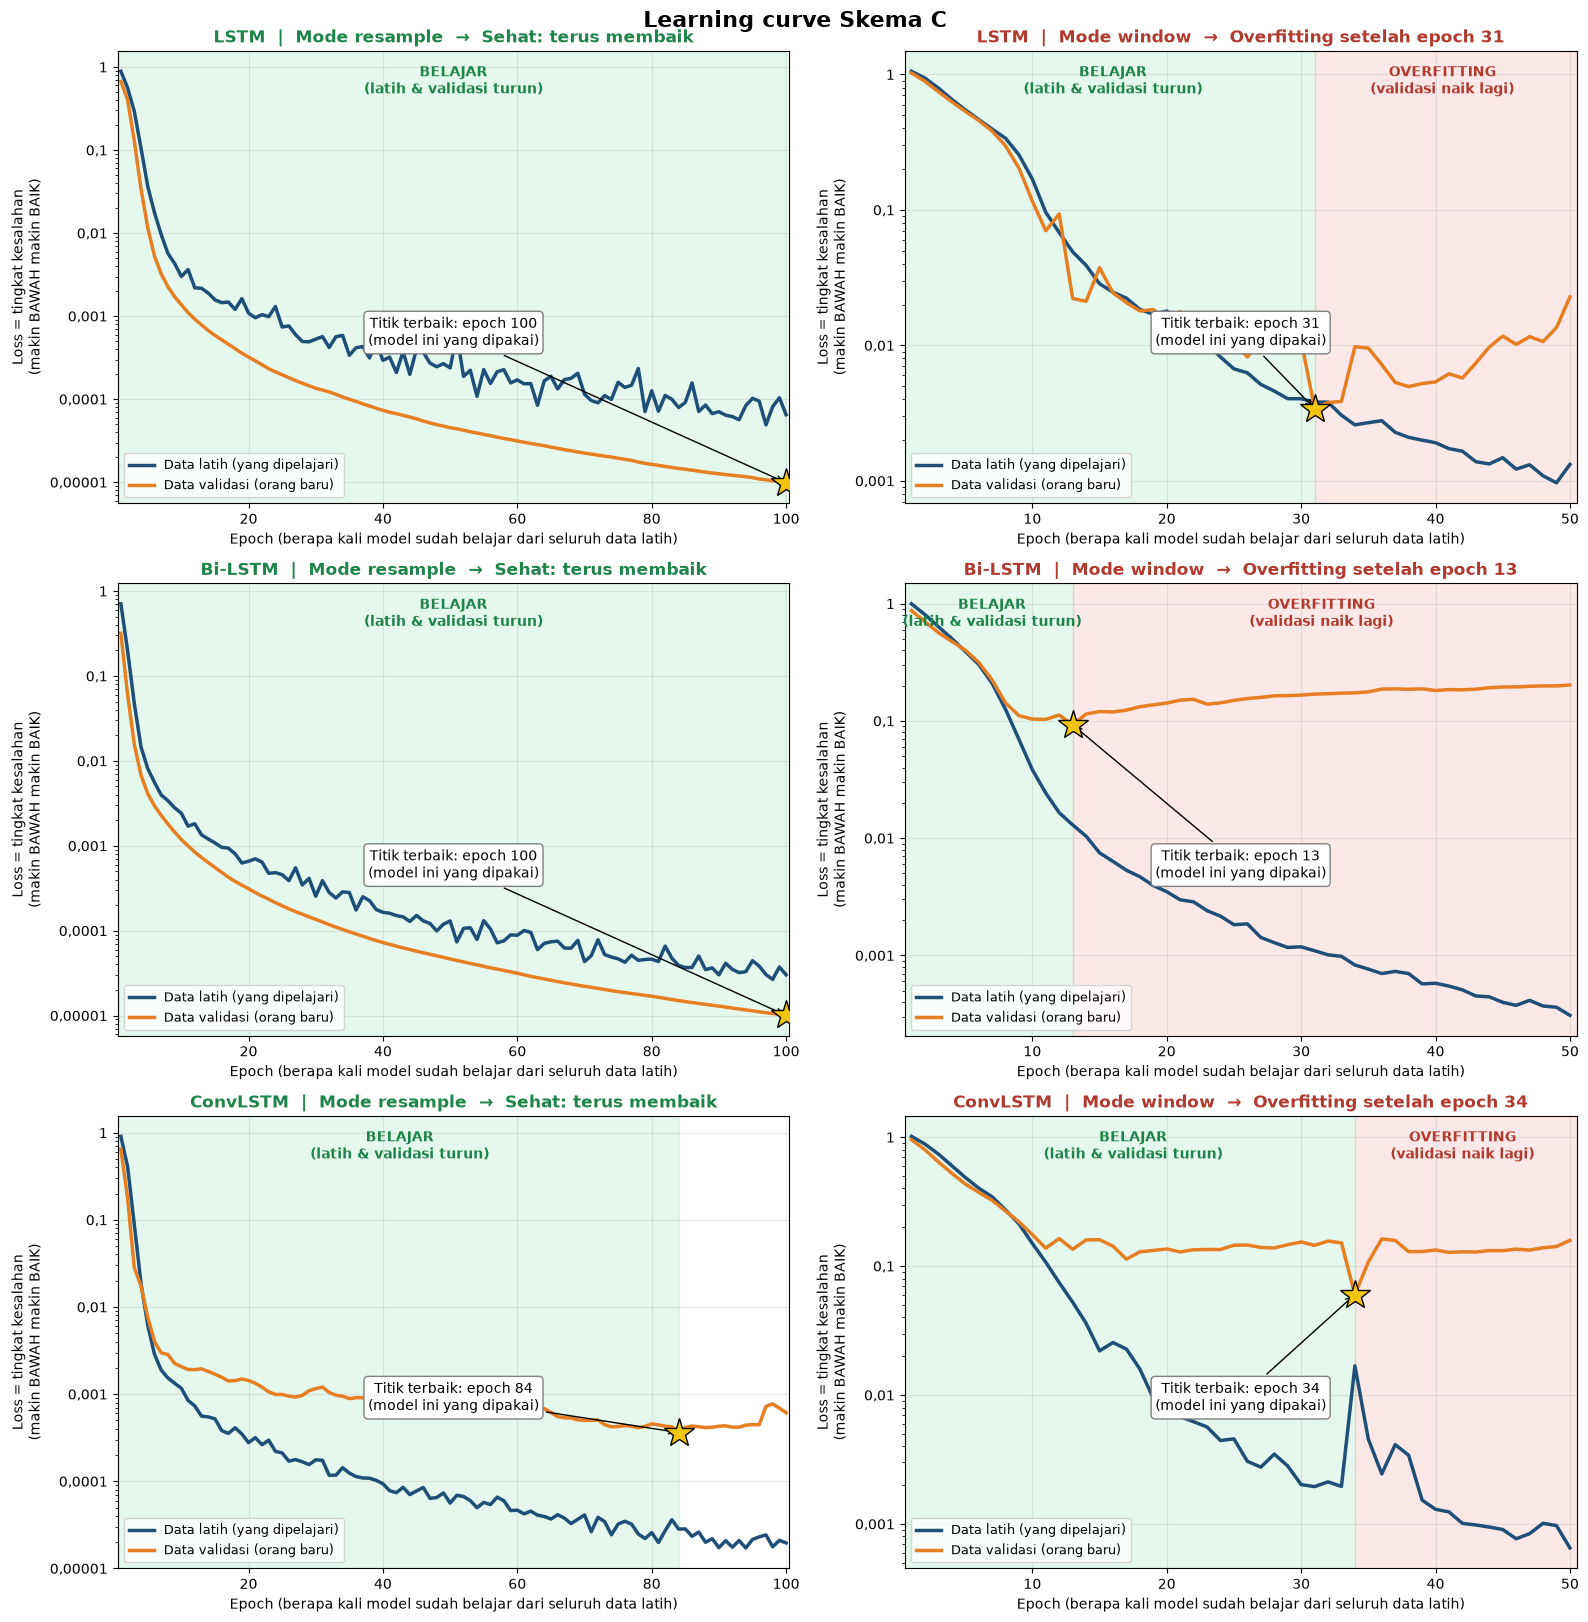

**3. Confusion matrix LOSO gabungan (240 video)**

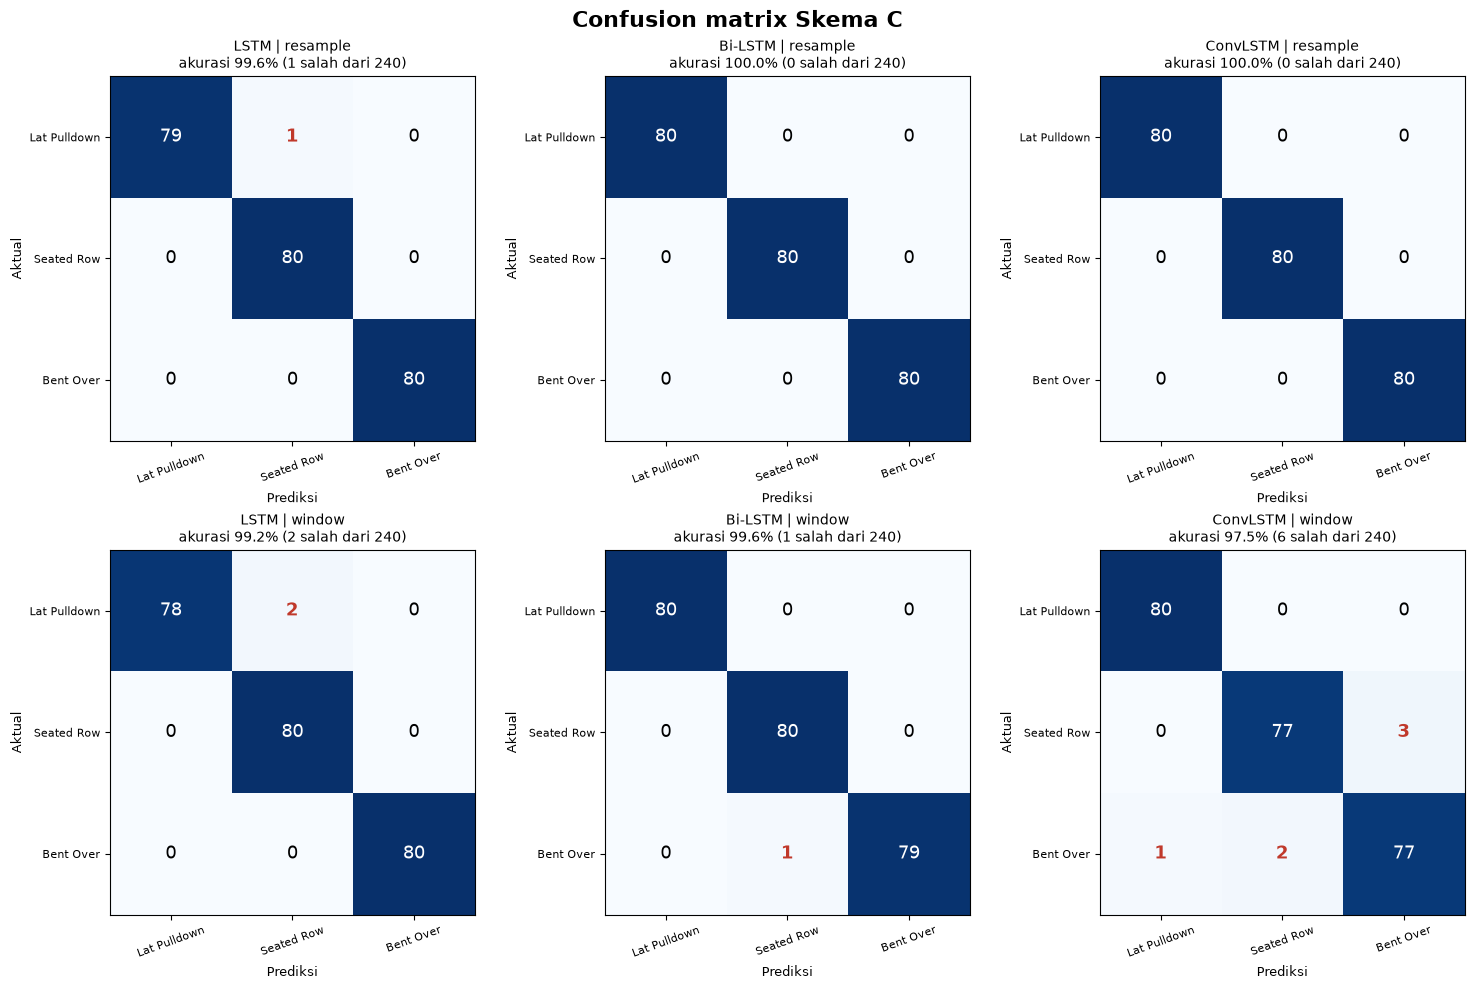

**4. Laporan per kelas (LOSO gabungan)**

--- LSTM | resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     0.988     0.994        80
Seated_Cable_Row      0.988     1.000     0.994        80
       Bent_over      1.000     1.000     1.000        80

        accuracy                          0.996       240
       macro avg      0.996     0.996     0.996       240
    weighted avg      0.996     0.996     0.996       240

--- LSTM | window ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     0.975     0.987        80
Seated_Cable_Row      0.976     1.000     0.988        80
       Bent_over      1.000     1.000     1.000        80

        accuracy                          0.992       240
       macro avg      0.992     0.992     0.992       240
    weighted avg      0.992     0.992     0.992       240

--- Bi-LSTM | resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000   

**5. Akurasi LOSO per subjek uji**

In [9]:
laporan_skema("C")

### 5.2 Skema D: Gerakan koordinat (52 fitur)

**1. Tabel metrik (LOSO rata-rata ± std)**

Akurasi        Presisi         Recall       F1-score  \
LSTM     resample   98.6% ± 2.9%   98.8% ± 2.4%   98.6% ± 2.9%   98.6% ± 3.0%   
         window     99.1% ± 2.8%   99.1% ± 2.8%   99.1% ± 2.8%   99.1% ± 2.8%   
Bi-LSTM  resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
         window    100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
ConvLSTM resample   99.8% ± 0.7%   99.8% ± 0.7%   99.8% ± 0.7%   99.8% ± 0.7%   
         window     95.1% ± 7.8%   96.7% ± 5.1%   95.1% ± 7.8%   94.8% ± 8.5%   

                  Holdout akurasi Urutan diacak Parameter Waktu/run (detik)  
LSTM     resample          100.0%         55.6%    43.523                21  
         window            100.0%         92.1%    43.523                48  
Bi-LSTM  resample          100.0%         56.3%   103.299                55  
         window            100.0%         92.4%   103.299               108  
ConvLSTM resample          100.0%         38.2%    30.019               397  
         window            100.0%         73.1%    30.019               256

**2. Learning curve (run holdout)**

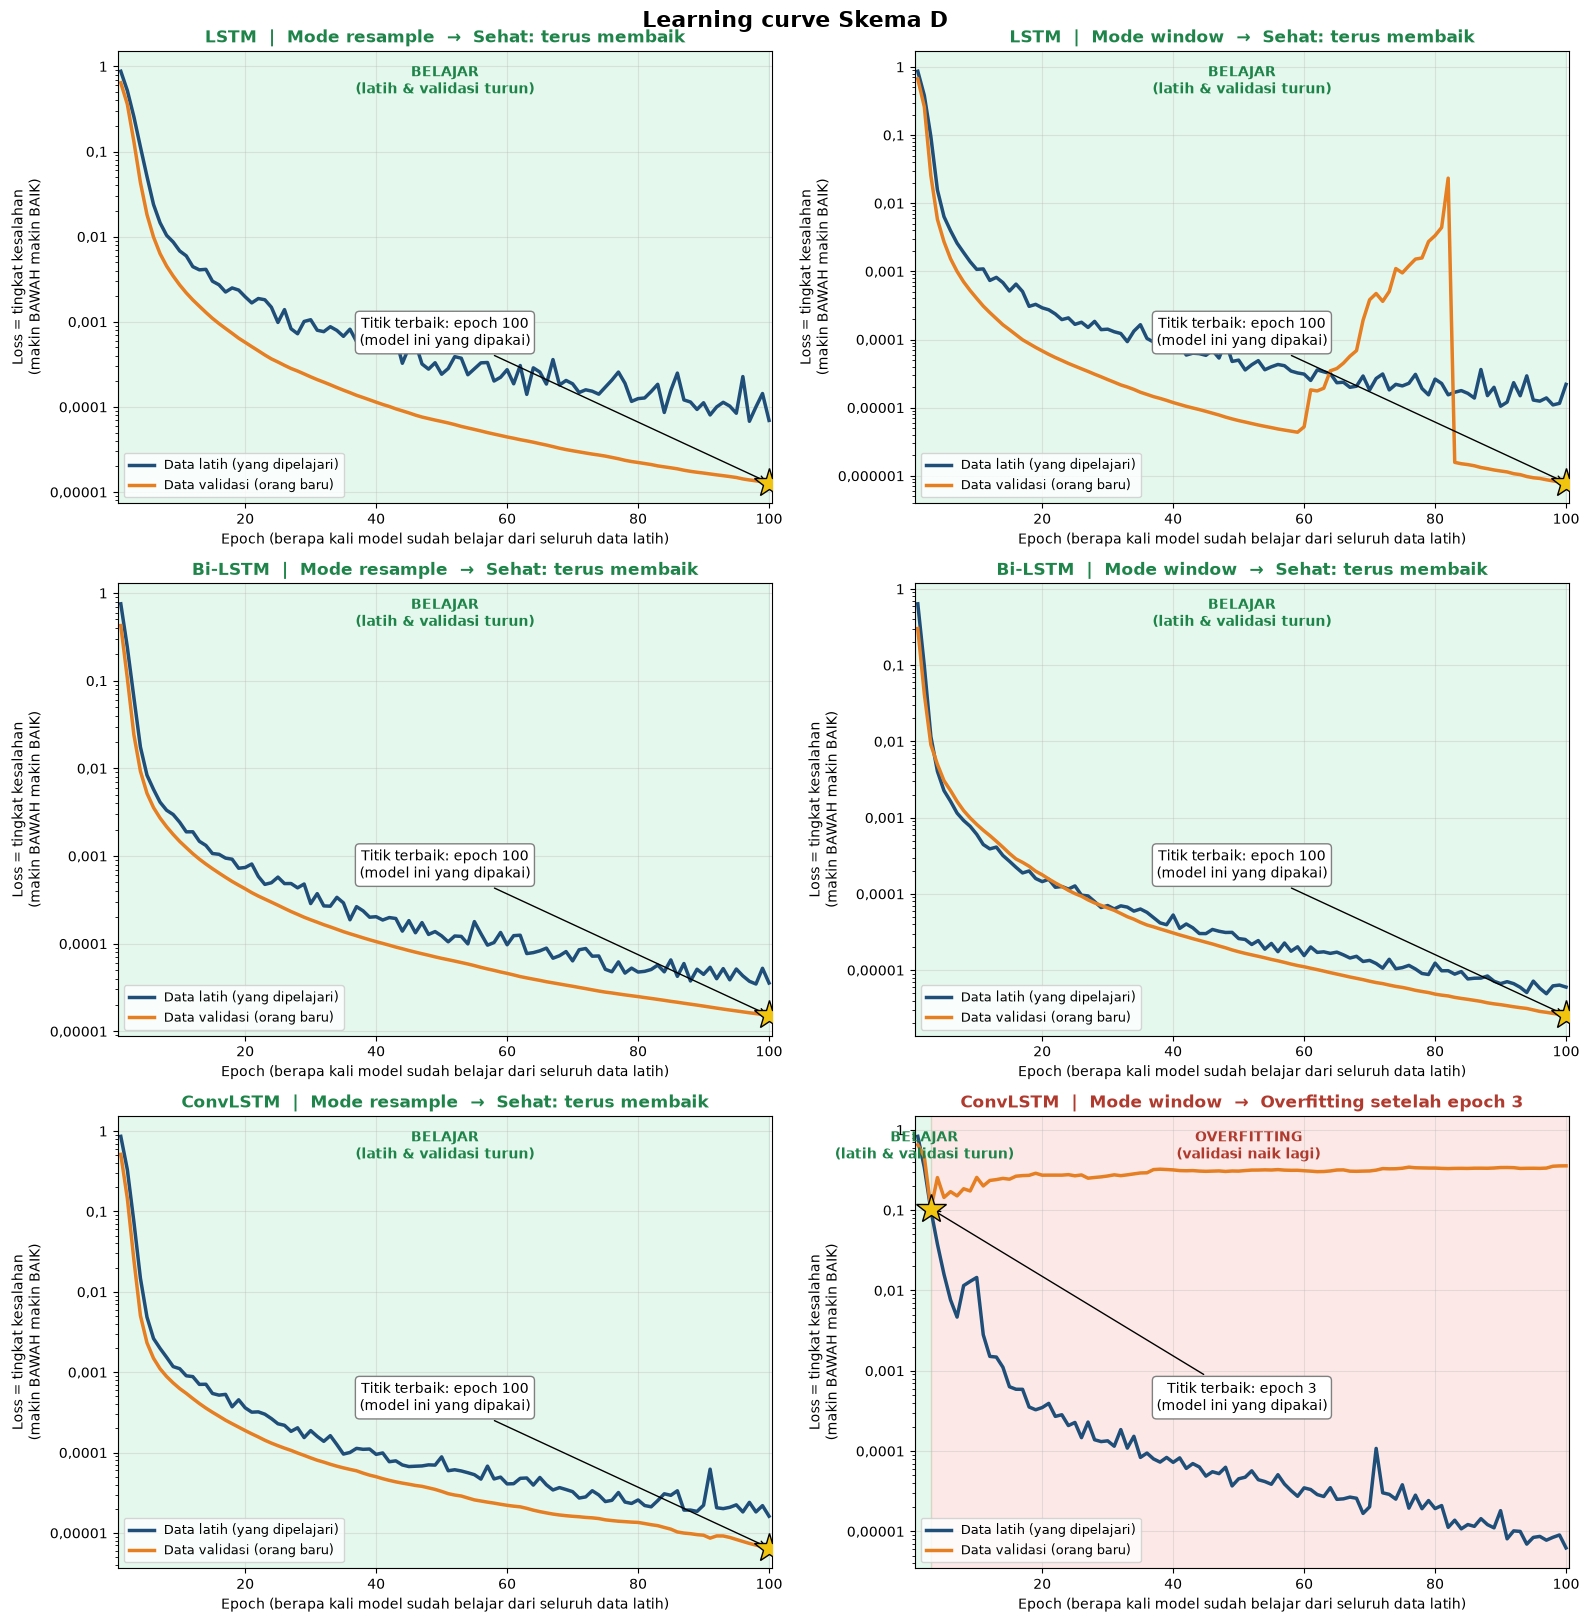

**3. Confusion matrix LOSO gabungan (240 video)**

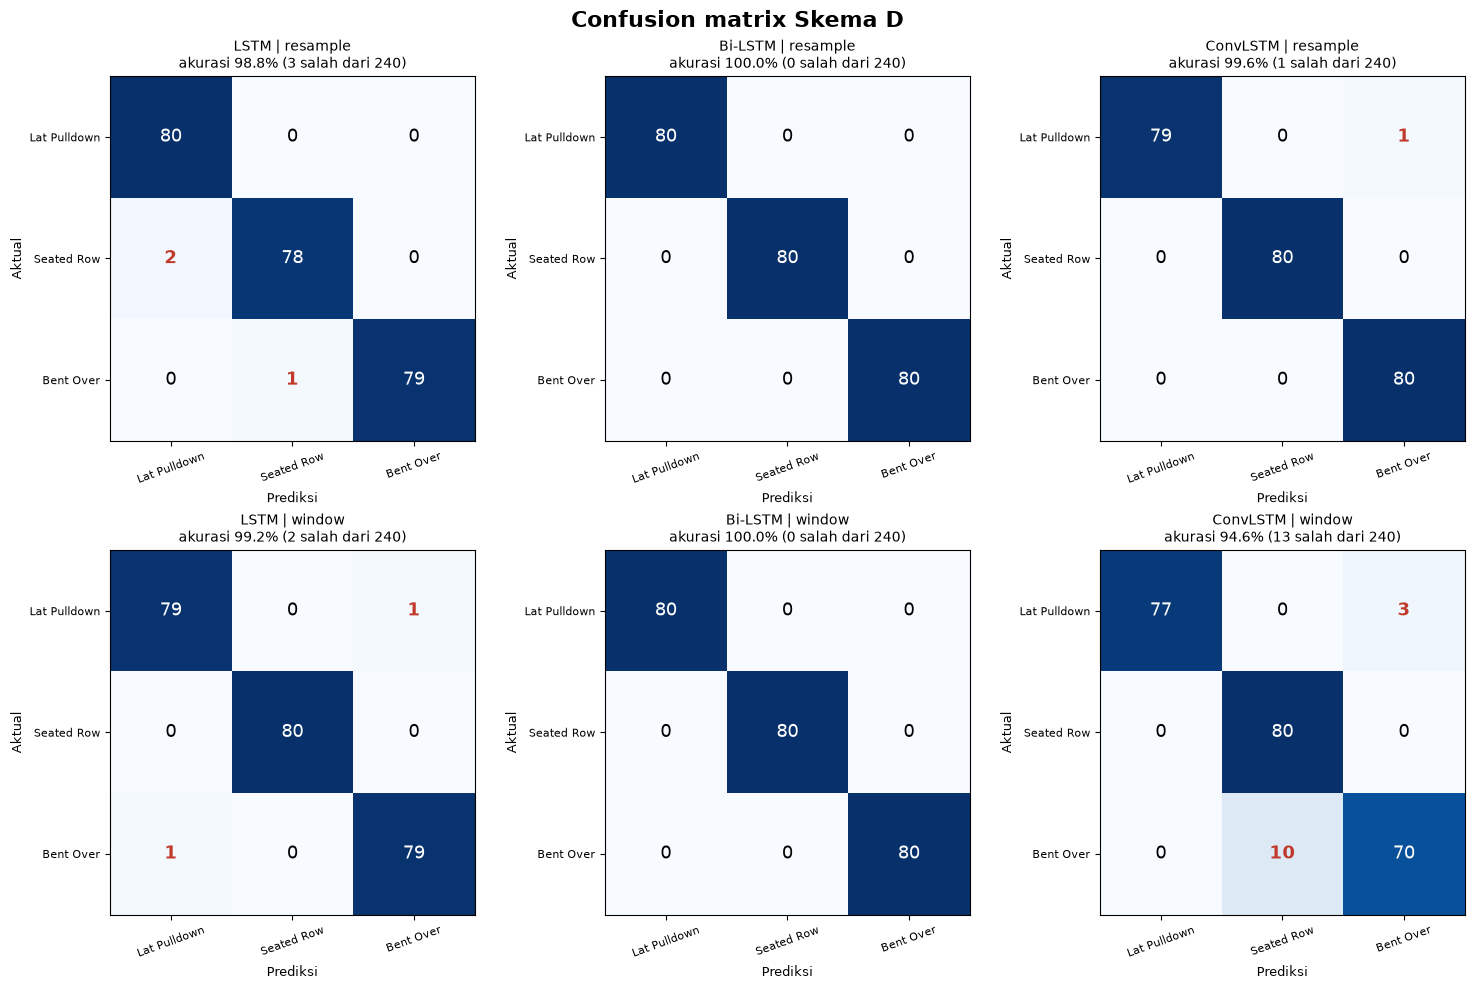

**4. Laporan per kelas (LOSO gabungan)**

--- LSTM | resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      0.976     1.000     0.988        80
Seated_Cable_Row      0.987     0.975     0.981        80
       Bent_over      1.000     0.988     0.994        80

        accuracy                          0.988       240
       macro avg      0.988     0.988     0.987       240
    weighted avg      0.988     0.988     0.987       240

--- LSTM | window ---
                  precision    recall  f1-score   support

    Lat_Pulldown      0.988     0.988     0.988        80
Seated_Cable_Row      1.000     1.000     1.000        80
       Bent_over      0.988     0.988     0.988        80

        accuracy                          0.992       240
       macro avg      0.992     0.992     0.992       240
    weighted avg      0.992     0.992     0.992       240

--- Bi-LSTM | resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000   

**5. Akurasi LOSO per subjek uji**

In [10]:
laporan_skema("D")

## 6. Ringkasan Perbandingan Model

**💡 Penjelasan kode**

- Tabel `summary`: satu baris per model × skema × mode, berisi rata-rata dan standar deviasi 4 metrik LOSO, akurasi holdout, akurasi urutan diacak, jumlah parameter, waktu training rata-rata, dan jumlah video yang salah. Disimpan ke `summary.csv`.
- `salah (dari 240)`: jumlah video yang salah ditebak di LOSO gabungan. Lebih mudah dibayangkan daripada persentase.

In [11]:
loso = runs[runs.fold.str.startswith("loso")]
grp = loso.groupby(["model", "scheme", "mode"], sort=False)
summary = grp[METRICS].agg(["mean", "std"])
summary.columns = [f"loso_{a}_{b}" for a, b in summary.columns]
summary["loso_shuffled_accuracy"] = grp.shuffled_accuracy.mean()
summary["holdout_accuracy"] = runs[runs.fold == "holdout"].set_index(["model", "scheme", "mode"]).accuracy
summary["n_params"] = grp.n_params.first()
summary["train_seconds_mean"] = runs.groupby(["model", "scheme", "mode"], sort=False).train_seconds.mean()
pl = preds[preds.fold.str.startswith("loso")]
summary["salah_dari_240"] = (pl.label != pl.pred).groupby([pl.model, pl.scheme, pl["mode"]]).sum()
summary.to_csv(OUT_DIR / "summary.csv")

show = pd.DataFrame(index=summary.index)
for k in METRICS:
    show[METRIC_ID[k]] = [f"{a:.1%} ± {b:.1%}" for a, b in zip(summary[f"loso_{k}_mean"], summary[f"loso_{k}_std"])]
show["Salah (dari 240)"] = summary.salah_dari_240.astype(int)
show["Urutan diacak"] = summary.loso_shuffled_accuracy.map("{:.1%}".format)
show["Parameter"] = summary.n_params.map(lambda v: f"{int(v):,}".replace(",", "."))
show["Waktu/run (detik)"] = summary.train_seconds_mean.map("{:.0f}".format)
show

Akurasi        Presisi         Recall  \
model    scheme mode                                                    
LSTM     C      resample   99.8% ± 0.7%   99.8% ± 0.7%   99.8% ± 0.7%   
                window     99.1% ± 2.8%   99.3% ± 2.2%   99.1% ± 2.8%   
         D      resample   98.6% ± 2.9%   98.8% ± 2.4%   98.6% ± 2.9%   
                window     99.1% ± 2.8%   99.1% ± 2.8%   99.1% ± 2.8%   
Bi-LSTM  C      resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
                window     99.5% ± 1.4%   99.6% ± 1.2%   99.5% ± 1.4%   
         D      resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
                window    100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
ConvLSTM C      resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
                window     97.2% ± 5.9%   97.7% ± 4.8%   97.2% ± 5.9%   
         D      resample   99.8% ± 0.7%   99.8% ± 0.7%   99.8% ± 0.7%   
                window     95.1% ± 7.8%   96.7% ± 5.1%   95.1% ± 7.8%   

                               F1-score  Salah (dari 240) Urutan diacak  \
model    scheme mode                                                      
LSTM     C      resample   99.8% ± 0.7%                 1         37.7%   
                window     99.1% ± 2.8%                 2         71.5%   
         D      resample   98.6% ± 3.0%                 3         55.6%   
                window     99.1% ± 2.8%                 2         92.1%   
Bi-LSTM  C      resample  100.0% ± 0.0%                 0         53.2%   
                window     99.5% ± 1.4%                 1         76.2%   
         D      resample  100.0% ± 0.0%                 0         56.2%   
                window    100.0% ± 0.0%                 0         92.4%   
ConvLSTM C      resample  100.0% ± 0.0%                 0         41.7%   
                window     97.2% ± 6.0%                 6         44.7%   
         D      resample   99.8% ± 0.7%                 1         38.2%   
                window     94.8% ± 8.5%                13         73.1%   

                         Parameter Waktu/run (detik)  
model    scheme mode                                  
LSTM     C      resample    34.307                17  
                window      34.307                29  
         D      resample    43.523                21  
                window      43.523                48  
Bi-LSTM  C      resample    84.867                48  
                window      84.867                75  
         D      resample   103.299                55  
                window     103.299               108  
ConvLSTM C      resample    26.691                89  
                window      26.691               134  
         D      resample    30.019               397  
                window      30.019               256

**💡 Penjelasan kode**

Grafik perbandingan dalam satu gambar dengan tiga panel:
- **Kiri**: akurasi LOSO (± std) setiap model untuk keempat kombinasi skema × mode. Makin tinggi dan makin pendek garis std, makin baik.
- **Tengah**: akurasi saat urutan diacak. Makin **rendah** (mendekati 33%), makin model bergantung pada urutan gerakan.
- **Kanan**: waktu training rata-rata per run. Makin rendah makin ringan.

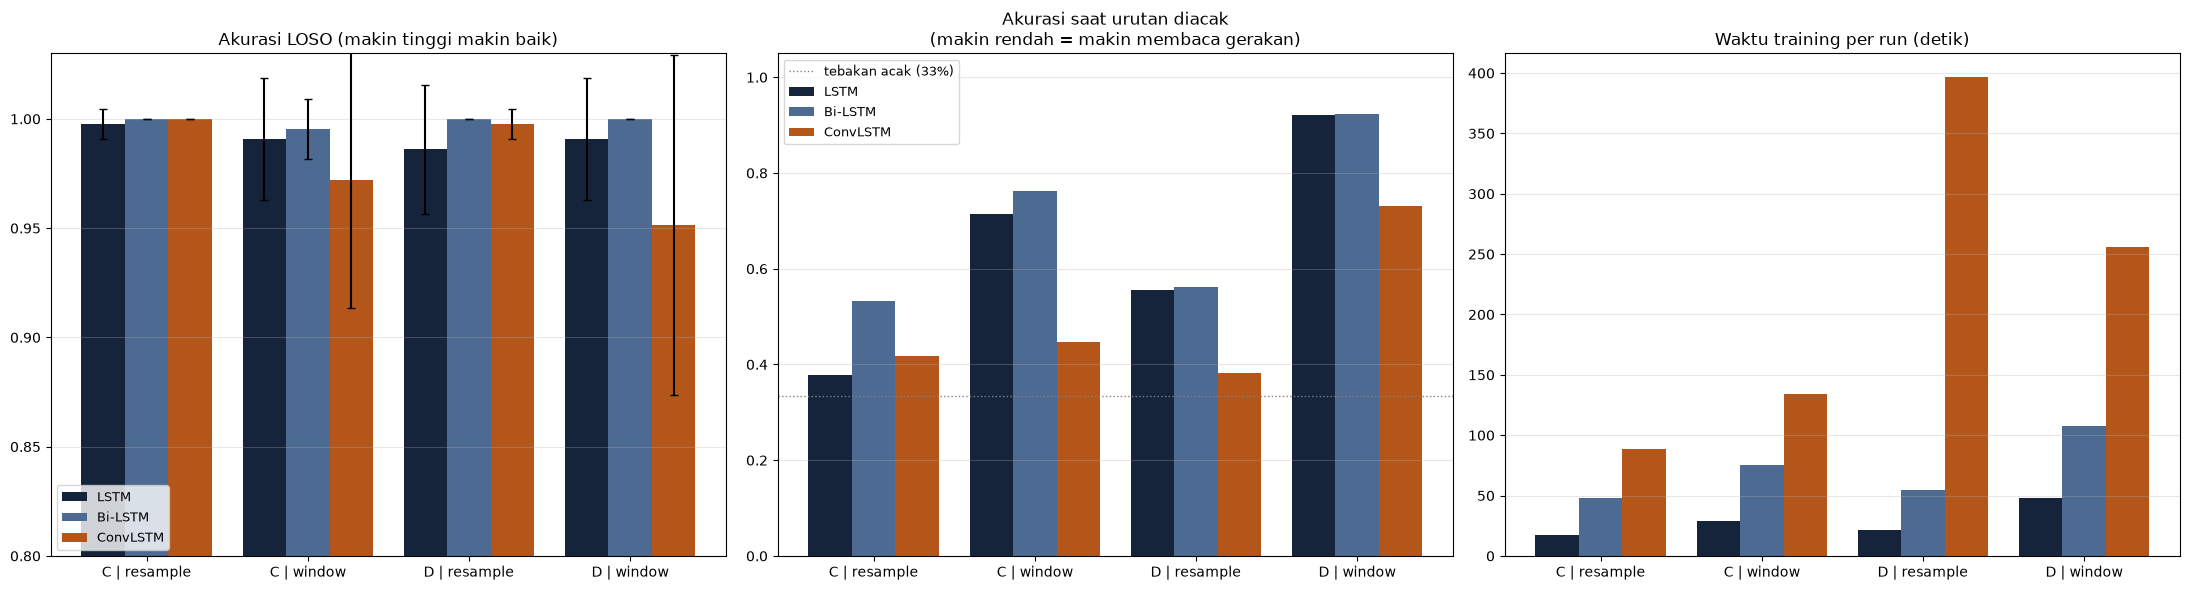

In [12]:
combos = [(s, m) for s in SCHEMES for m in SEQ_MODES]
labels = [f"{s} | {m}" for s, m in combos]
colors = {"LSTM": "#15233B", "Bi-LSTM": "#4C6A92", "ConvLSTM": "#B4561A"}
x = np.arange(len(combos))
w = 0.27

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for i, arch in enumerate(MODELS):
    acc = [summary.loc[(arch, s, m), "loso_accuracy_mean"] for s, m in combos]
    std = [summary.loc[(arch, s, m), "loso_accuracy_std"] for s, m in combos]
    shuf = [summary.loc[(arch, s, m), "loso_shuffled_accuracy"] for s, m in combos]
    secs = [summary.loc[(arch, s, m), "train_seconds_mean"] for s, m in combos]
    axes[0].bar(x + (i - 1) * w, acc, w, yerr=std, capsize=3, color=colors[arch], label=arch)
    axes[1].bar(x + (i - 1) * w, shuf, w, color=colors[arch], label=arch)
    axes[2].bar(x + (i - 1) * w, secs, w, color=colors[arch], label=arch)

low = min(0.8, summary.loso_accuracy_mean.min() - 0.05)  # batas bawah otomatis supaya batang tidak terpotong
axes[0].set(title="Akurasi LOSO (makin tinggi makin baik)", ylim=(low, 1.03))
axes[1].set(title="Akurasi saat urutan diacak\n(makin rendah = makin membaca gerakan)", ylim=(0, 1.05))
axes[1].axhline(1 / 3, color="gray", ls=":", lw=1, label="tebakan acak (33%)")
axes[2].set(title="Waktu training per run (detik)")
for ax in axes:
    ax.set_xticks(x, labels)
    ax.grid(axis="y", alpha=0.3)
axes[1].legend(fontsize=9)
axes[0].legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "ringkasan_perbandingan_model.png", dpi=150)
plt.show()

### Cara membaca hasil

| Pertanyaan | Lihat | Model lebih baik jika |
|---|---|---|
| Model mana yang paling akurat? | akurasi & F1 LOSO, jumlah video salah | akurasi tinggi, std kecil, sedikit video salah |
| Model mana yang paling stabil untuk semua orang? | std LOSO, tabel per subjek | std kecil, tidak ada subjek yang jauh di bawah |
| Apakah model membaca urutan gerakan? | akurasi urutan diacak | turun mendekati 33% |
| Apakah training sehat? | learning curve | hijau, tidak ada zona merah/kuning |
| Model mana yang paling ringan? | jumlah parameter, waktu training | parameter dan waktu kecil |

Jika akurasi ketiga model hampir sama (selisih ≤ 1–2 video dari 240), model yang **lebih sederhana dan lebih cepat** lebih disarankan. Selisih sekecil itu belum tentu bermakna tanpa uji statistik.